# Network Intrusion Detection on UNSW-NB15

Classifying network flows as **normal vs. attack** (binary) and into **10 traffic categories** (normal + 9 attack types), with the evaluation choices a security team actually cares about:

- **False alarms matter.** Beyond accuracy, I report PR-AUC and the recall achievable at a **≤1% false-positive rate**, with the threshold chosen on a validation split and applied once to the test set.
- **Rare attacks matter.** Attack categories are heavily imbalanced (Worms is ~300× rarer than Generic), so I report per-class precision/recall and test class weighting.
- **Results should be trusted only after checks.** The notebook tests two ways the headline numbers could be inflated: train/test duplicate rows and a known TTL artifact in this dataset.

**Dataset:** UNSW-NB15 official partitioned sets — training 175,341 flows, testing 82,332 flows (Cyber Range Lab, UNSW Canberra).
Citation: N. Moustafa and J. Slay, "UNSW-NB15: a comprehensive data set for network intrusion detection systems," *MilCIS 2015*, IEEE.
Place `UNSW_NB15_training-set.csv` and `UNSW_NB15_testing-set.csv` in a `data/` folder next to this notebook.

## 1. Imports & data

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score, precision_score,
                             recall_score, f1_score, roc_curve, precision_recall_curve,
                             classification_report, confusion_matrix)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
DATA_DIR = Path("data")

# Some public copies swap the two file names, so identify the official split by row count:
# official training set = 175,341 rows, official testing set = 82,332 rows.
frames = [pd.read_csv(p, encoding="utf-8-sig") for p in sorted(DATA_DIR.glob("UNSW_NB15_*-set.csv"))]
train_df = next(f for f in frames if len(f) == 175_341)
test_df = next(f for f in frames if len(f) == 82_332)
print("Train:", train_df.shape, "| Test:", test_df.shape)

Train: (175341, 45) | Test: (82332, 45)


## 2. Exploratory analysis — how imbalanced is the problem?

At the binary level attacks are actually the *majority* (~68% of training flows), because the lab generated a lot of attack traffic. The real imbalance is **between attack types**.

,train,test,train_share_%
attack_cat,,,
Normal,56000,37000,31.94
Generic,40000,18871,22.81
Exploits,33393,11132,19.04
Fuzzers,18184,6062,10.37
DoS,12264,4089,6.99
Reconnaissance,10491,3496,5.98
Analysis,2000,677,1.14
Backdoor,1746,583,1.00
Shellcode,1133,378,0.65


Binary label share (train): {1: 0.681, 0: 0.319}


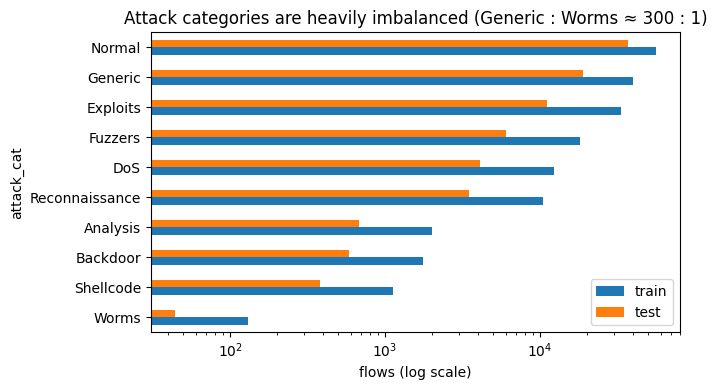

In [2]:
cats = pd.DataFrame({"train": train_df.attack_cat.value_counts(),
                     "test": test_df.attack_cat.value_counts()})
cats["train_share_%"] = (100 * cats.train / cats.train.sum()).round(2)
display(cats)
print("Binary label share (train):", train_df.label.value_counts(normalize=True).round(3).to_dict())

ax = cats[["train", "test"]].sort_values("train").plot.barh(logx=True, figsize=(7, 4))
ax.set_xlabel("flows (log scale)")
ax.set_title("Attack categories are heavily imbalanced (Generic : Worms ≈ 300 : 1)")
plt.tight_layout()
plt.show()

## 3. Data-quality and leakage checks (before any modelling)

Three things could make results look better than they are:
1. **Duplicates** — identical flows inside the training set, and test rows that also appear in training.
2. **Identifier columns** — `id` restarts in each file and carries no information; `attack_cat` *is* the answer for the binary task. Both are excluded from features.
3. **Testbed artifacts** — in UNSW-NB15, TTL values reflect how the lab was wired, not attacker behaviour.

In [3]:
FEATURES = [c for c in train_df.columns if c not in ("id", "attack_cat", "label")]
CAT_COLS = ["proto", "service", "state"]
NUM_COLS = [c for c in FEATURES if c not in CAT_COLS]
print(f"{len(FEATURES)} features: {len(CAT_COLS)} categorical + {len(NUM_COLS)} numeric")

dup_train = train_df.duplicated(subset=FEATURES).sum()
train_keys = set(map(tuple, train_df[FEATURES].astype(str).values))
in_train = np.array([tuple(r) in train_keys for r in test_df[FEATURES].astype(str).values])
print(f"Duplicate feature rows inside train: {dup_train:,} ({dup_train / len(train_df):.1%})")
print(f"Test rows whose exact features also appear in train: {in_train.sum():,} ({in_train.mean():.1%})")
print("Test 'state' values never seen in train:", sorted(set(test_df.state) - set(train_df.state)))

42 features: 3 categorical + 39 numeric
Duplicate feature rows inside train: 74,301 (42.4%)
Test rows whose exact features also appear in train: 8,541 (10.4%)
Test 'state' values never seen in train: ['ACC', 'CLO']


In [4]:
ttl = pd.crosstab(train_df.sttl, train_df.label)
print("Source TTL (sttl) vs label in training data — values with >500 flows:")
display(ttl[ttl.sum(axis=1) > 500])

Source TTL (sttl) vs label in training data — values with >500 flows:


label,0,1
sttl,,
0,2859,303
31,39455,0
62,2167,15514
254,11230,103513


**Finding:** every one of the ~39k flows with `sttl = 31` is normal traffic — zero attacks. That is a property of the lab network, not of attacks, and a model can learn it as a shortcut. I keep TTL features in the main models (they are part of the standard benchmark) but test in Section 8 how much performance depends on them.

## 4. Preprocessing and splits

- Categorical columns → one-hot (`handle_unknown="ignore"`, because the test set has connection states never seen in training; rare categories grouped).
- Logistic Regression gets `log1p` + standardisation (byte and packet counts are extremely heavy-tailed); tree models get raw values.
- 15% of the official training set is held out as a **validation split** used only to pick decision thresholds. The official test set is used once per model, for final numbers.

In [5]:
def make_preprocessor(num_cols, for_linear):
    num = Pipeline([("log", FunctionTransformer(np.log1p)), ("scale", StandardScaler())]) if for_linear else "passthrough"
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=False), CAT_COLS),
        ("num", num, num_cols),
    ])

X_fit, X_val, y_fit, y_val, cat_fit, cat_val = train_test_split(
    train_df[FEATURES], train_df.label, train_df.attack_cat,
    test_size=0.15, stratify=train_df.attack_cat, random_state=RANDOM_STATE)
X_test, y_test, cat_test = test_df[FEATURES], test_df.label, test_df.attack_cat
print(f"fit: {len(X_fit):,} | validation: {len(X_val):,} | test: {len(X_test):,}")

fit: 149,039 | validation: 26,302 | test: 82,332


## 5. Binary detection: normal vs. attack

Two operating points are reported for every model:
- the default threshold of 0.5, and
- the threshold that gives the **highest recall with ≤1% false-positive rate on the validation split**, then applied unchanged to the test set (the test FPR it actually achieves is reported too — it will not be exactly 1%).

In [6]:
def evaluate_binary(name, model, X_val, y_val, X_test, y_test, max_fpr=0.01):
    p_val = model.predict_proba(X_val)[:, 1]
    p_test = model.predict_proba(X_test)[:, 1]
    fpr, tpr, thr = roc_curve(y_val, p_val)
    t_low = thr[np.where(fpr <= max_fpr)[0][-1]]
    neg = (y_test == 0).values
    at05, atlow = p_test >= 0.5, p_test >= t_low
    return {
        "model": name,
        "ROC-AUC": roc_auc_score(y_test, p_test),
        "PR-AUC": average_precision_score(y_test, p_test),
        "accuracy@0.5": accuracy_score(y_test, at05),
        "precision@0.5": precision_score(y_test, at05),
        "recall@0.5": recall_score(y_test, at05),
        "FPR@0.5": at05[neg].mean(),
        "recall @ val-1%-FPR thr": recall_score(y_test, atlow),
        "test FPR @ that thr": atlow[neg].mean(),
    }, p_test, t_low

binary_models = {
    "Logistic Regression": Pipeline([("prep", make_preprocessor(NUM_COLS, True)),
                                     ("clf", LogisticRegression(max_iter=3000, class_weight="balanced"))]),
    "Random Forest": Pipeline([("prep", make_preprocessor(NUM_COLS, False)),
                               ("clf", RandomForestClassifier(n_estimators=200, min_samples_leaf=2,
                                                              n_jobs=-1, random_state=RANDOM_STATE))]),
    "Hist Gradient Boosting": Pipeline([("prep", make_preprocessor(NUM_COLS, False)),
                                        ("clf", HistGradientBoostingClassifier(max_iter=300, random_state=RANDOM_STATE))]),
}

rows, test_scores, low_thresholds = [], {}, {}
for name, model in binary_models.items():
    model.fit(X_fit, y_fit)
    r, p, t = evaluate_binary(name, model, X_val, y_val, X_test, y_test)
    rows.append(r); test_scores[name] = p; low_thresholds[name] = t

binary_results = pd.DataFrame(rows).set_index("model").round(4)
display(binary_results)

,ROC-AUC,PR-AUC,accuracy@0.5,precision@0.5,recall@0.5,FPR@0.5,recall @ val-1%-FPR thr,test FPR @ that thr
model,,,,,,,,
Logistic Regression,0.9673,0.9756,0.8686,0.8395,0.9413,0.2204,0.7919,0.0214
Random Forest,0.9826,0.9869,0.8666,0.8110,0.9880,0.2821,0.8918,0.0372
Hist Gradient Boosting,0.9840,0.9883,0.8720,0.8202,0.9830,0.2641,0.9127,0.0481


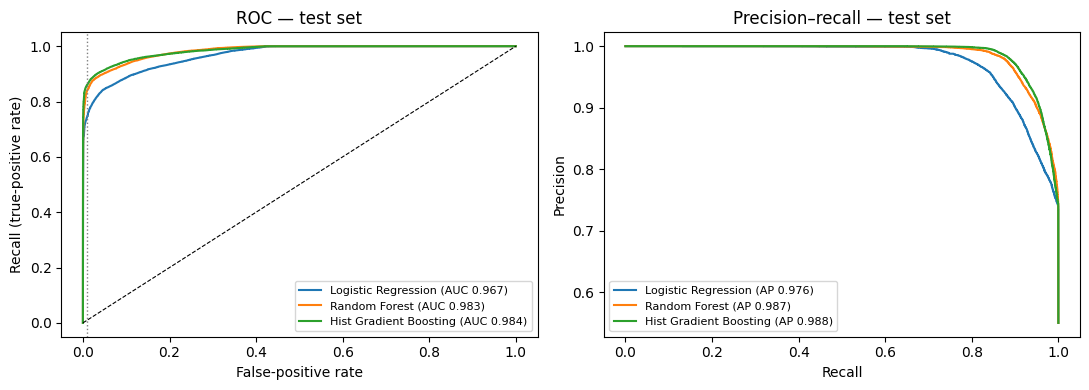

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, p in test_scores.items():
    f, t, _ = roc_curve(y_test, p)
    axes[0].plot(f, t, label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rc, pr, label=f"{name} (AP {average_precision_score(y_test, p):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[0].axvline(0.01, color="grey", ls=":", lw=1)
axes[0].set(xlabel="False-positive rate", ylabel="Recall (true-positive rate)", title="ROC — test set")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision–recall — test set")
for a in axes: a.legend(fontsize=8)
plt.tight_layout(); plt.show()

### Choosing the alert threshold
The default 0.5 threshold is arbitrary. Below, precision, recall and false-positive rate on the **validation split** as the threshold moves — this is the trade-off a SOC would tune (every false alarm costs analyst time; every miss is an undetected attack).

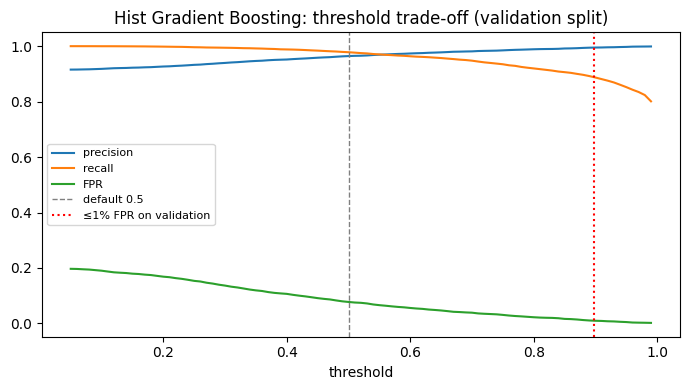

Best binary model by test PR-AUC: Hist Gradient Boosting; ≤1%-FPR threshold = 0.897


In [8]:
best_name = binary_results["PR-AUC"].idxmax()
best_model = binary_models[best_name]
p_val = best_model.predict_proba(X_val)[:, 1]
ths = np.linspace(0.05, 0.99, 95)
neg_val = (y_val == 0).values
curve = pd.DataFrame({
    "threshold": ths,
    "precision": [precision_score(y_val, p_val >= t, zero_division=1) for t in ths],
    "recall": [recall_score(y_val, p_val >= t) for t in ths],
    "FPR": [(p_val[neg_val] >= t).mean() for t in ths],
})
ax = curve.plot(x="threshold", y=["precision", "recall", "FPR"], figsize=(7, 4))
ax.axvline(0.5, color="grey", ls="--", lw=1, label="default 0.5")
ax.axvline(low_thresholds[best_name], color="red", ls=":", lw=1.5, label="≤1% FPR on validation")
ax.set_title(f"{best_name}: threshold trade-off (validation split)")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()
print(f"Best binary model by test PR-AUC: {best_name}; ≤1%-FPR threshold = {low_thresholds[best_name]:.3f}")

## 6. Multi-class: which kind of traffic is it?

Ten classes (Normal + 9 attack types). The question is how well the rare categories are recognised, and whether class weighting helps them. Macro-F1 (every class counts equally) is the headline metric here, not accuracy.

In [9]:
mc_models = {
    "RF (unweighted)": RandomForestClassifier(n_estimators=200, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE),
    "RF (balanced class weights)": RandomForestClassifier(n_estimators=200, min_samples_leaf=2, n_jobs=-1,
                                                          class_weight="balanced_subsample", random_state=RANDOM_STATE),
}
mc_preds, mc_summary = {}, []
for name, clf in mc_models.items():
    pipe = Pipeline([("prep", make_preprocessor(NUM_COLS, False)), ("clf", clf)]).fit(X_fit, cat_fit)
    pred = pipe.predict(X_test)
    mc_preds[name] = pred
    mc_summary.append({"model": name, "accuracy": accuracy_score(cat_test, pred),
                       "macro-F1": f1_score(cat_test, pred, average="macro"),
                       "weighted-F1": f1_score(cat_test, pred, average="weighted")})
display(pd.DataFrame(mc_summary).set_index("model").round(4))

labels = cats.sort_values("train", ascending=False).index.tolist()
per_class = pd.DataFrame({
    f"{name} recall": recall_score(cat_test, pred, labels=labels, average=None) for name, pred in mc_preds.items()
} | {
    f"{name} precision": precision_score(cat_test, pred, labels=labels, average=None, zero_division=0) for name, pred in mc_preds.items()
}, index=labels)
per_class.insert(0, "test support", cats.loc[labels, "test"].values)
display(per_class.round(3))

,accuracy,macro-F1,weighted-F1
model,,,
RF (unweighted),0.7611,0.4506,0.7732
RF (balanced class weights),0.7098,0.4804,0.7560


,test support,RF (unweighted) recall,RF (balanced class weights) recall,RF (unweighted) precision,RF (balanced class weights) precision
Normal,37000,0.753,0.669,0.964,0.982
Generic,18871,0.964,0.963,0.999,1.000
Exploits,11132,0.863,0.643,0.580,0.759
Fuzzers,6062,0.600,0.656,0.294,0.268
DoS,4089,0.073,0.235,0.561,0.283
Reconnaissance,3496,0.795,0.830,0.917,0.872
Analysis,677,0.009,0.021,0.007,0.008
Backdoor,583,0.053,0.274,0.024,0.034
Shellcode,378,0.659,0.854,0.435,0.226
Worms,44,0.023,0.386,1.000,0.447


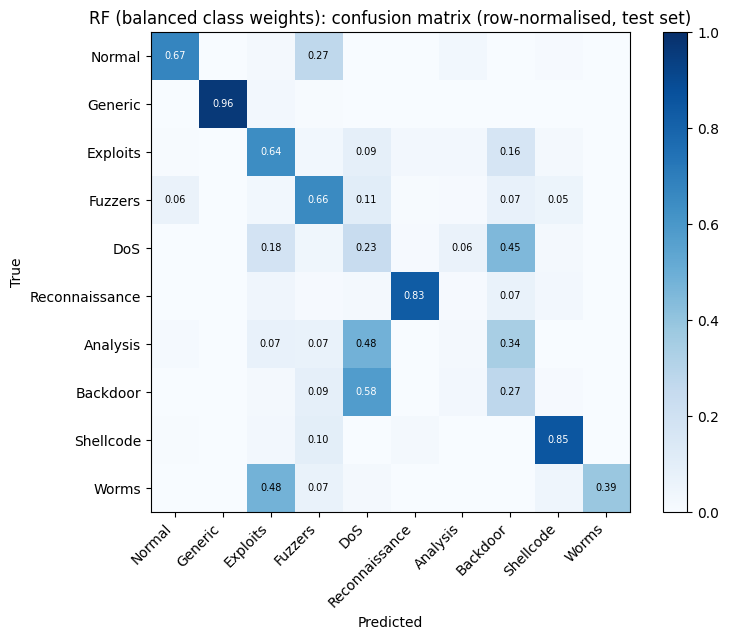

In [10]:
best_mc = max(mc_summary, key=lambda r: r["macro-F1"])["model"]
cm = confusion_matrix(cat_test, mc_preds[best_mc], labels=labels, normalize="true")
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(labels)), labels, rotation=45, ha="right"); ax.set_yticks(range(len(labels)), labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        if cm[i, j] >= 0.05:
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if cm[i, j] > 0.5 else "black")
ax.set(xlabel="Predicted", ylabel="True", title=f"{best_mc}: confusion matrix (row-normalised, test set)")
fig.colorbar(im, fraction=0.046); plt.tight_layout(); plt.show()

### Why are DoS, Analysis and Backdoor so hard?
If two flows have *identical* feature values but different labels, no model using these features can separate them. Count how often that happens per category in the training data.

In [11]:
row_key = train_df[FEATURES].astype(str).agg("|".join, axis=1)
n_labels_for_key = train_df.groupby(row_key).attack_cat.transform("nunique")
conflict = pd.DataFrame({
    "train rows": train_df.attack_cat.value_counts(),
    "rows sharing identical features with another category": train_df[n_labels_for_key > 1].attack_cat.value_counts(),
}).fillna(0).astype(int)
conflict["share"] = (conflict.iloc[:, 1] / conflict.iloc[:, 0]).round(3)
display(conflict.sort_values("share", ascending=False))
print(f"Overall: {(n_labels_for_key > 1).mean():.1%} of training rows have a feature-identical twin with a different category.")

,train rows,rows sharing identical features with another category,share
attack_cat,,,
DoS,12264,9746,0.795
Backdoor,1746,1340,0.767
Analysis,2000,1441,0.720
Exploits,33393,13299,0.398
Reconnaissance,10491,1889,0.180
Fuzzers,18184,2078,0.114
Worms,130,13,0.100
Generic,40000,319,0.008
Normal,56000,396,0.007


Overall: 17.4% of training rows have a feature-identical twin with a different category.


## 7. What does the detector rely on?

Permutation importance on the test set: shuffle one raw feature at a time and measure how much PR-AUC drops. Unlike impurity-based importance, this is measured on held-out data and is not biased toward high-cardinality features.

,PR-AUC drop when shuffled
sttl,0.1253
service,0.0191
sbytes,0.0177
ct_dst_sport_ltm,0.0102
ct_dst_src_ltm,0.0075
proto,0.0073
smean,0.0062
dbytes,0.0055
ct_srv_src,0.0049
dload,0.0047


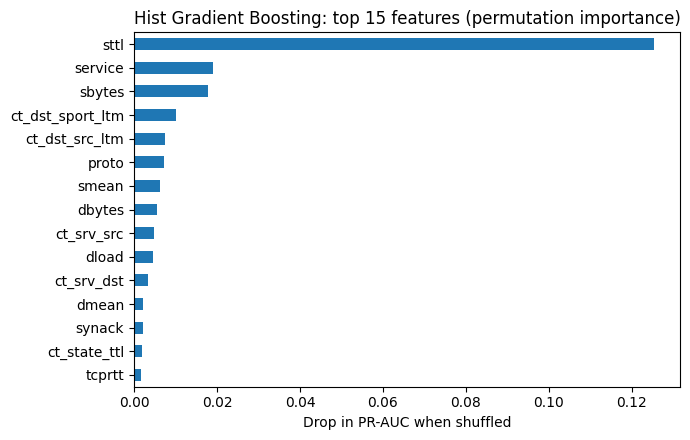

In [12]:
sample = test_df.groupby("label", group_keys=False).sample(n=4000, random_state=RANDOM_STATE)
perm = permutation_importance(best_model, sample[FEATURES], sample.label, scoring="average_precision",
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=FEATURES).sort_values(ascending=False)
display(imp.head(10).round(4).to_frame("PR-AUC drop when shuffled"))
ax = imp.head(15)[::-1].plot.barh(figsize=(7, 4.5))
ax.set(xlabel="Drop in PR-AUC when shuffled", title=f"{best_name}: top 15 features (permutation importance)")
plt.tight_layout(); plt.show()

## 8. Robustness checks

### 8a. How much does the model depend on the TTL artifact?
Retrain the best binary model **without** `sttl`, `dttl` and `ct_state_ttl` and compare.

In [13]:
TTL_COLS = ["sttl", "dttl", "ct_state_ttl"]
feats_no_ttl = [c for c in FEATURES if c not in TTL_COLS]
num_no_ttl = [c for c in NUM_COLS if c not in TTL_COLS]
no_ttl = Pipeline([("prep", make_preprocessor(num_no_ttl, best_name == "Logistic Regression")),
                   ("clf", binary_models[best_name].named_steps["clf"].__class__(**binary_models[best_name].named_steps["clf"].get_params()))])
no_ttl.fit(X_fit[feats_no_ttl], y_fit)
r_no_ttl, _, _ = evaluate_binary(f"{best_name} without TTL features", no_ttl,
                                 X_val[feats_no_ttl], y_val, X_test[feats_no_ttl], y_test)
ttl_compare = pd.DataFrame([binary_results.loc[best_name].rename(f"{best_name} (all features)"),
                            pd.Series(r_no_ttl).drop("model").rename(r_no_ttl["model"])]).astype(float).round(4)
display(ttl_compare)

,ROC-AUC,PR-AUC,accuracy@0.5,precision@0.5,recall@0.5,FPR@0.5,recall @ val-1%-FPR thr,test FPR @ that thr
Hist Gradient Boosting (all features),0.9840,0.9883,0.8720,0.8202,0.983,0.2641,0.9127,0.0481
Hist Gradient Boosting without TTL features,0.9814,0.9865,0.8695,0.8198,0.978,0.2634,0.8995,0.0429


### 8b. Are the test results inflated by rows the model already saw?
Split the test set into flows that also appear (exactly) in training and flows that do not.

In [14]:
p_best = test_scores[best_name]
t_best = low_thresholds[best_name]
overlap_rows = []
for subset, mask in [("test rows also in train", in_train), ("test rows NOT in train", ~in_train), ("all test rows", np.ones_like(in_train))]:
    y_s, p_s = y_test.values[mask], p_best[mask]
    overlap_rows.append({"subset": subset, "rows": int(mask.sum()), "attack share": y_s.mean(),
                         "ROC-AUC": roc_auc_score(y_s, p_s) if len(set(y_s)) > 1 else np.nan,
                         "PR-AUC": average_precision_score(y_s, p_s) if len(set(y_s)) > 1 else np.nan,
                         "recall @ val-1%-FPR thr": recall_score(y_s, p_s >= t_best),
                         "FPR @ that thr": (p_s[y_s == 0] >= t_best).mean() if (y_s == 0).any() else np.nan})
display(pd.DataFrame(overlap_rows).set_index("subset").round(4))

,rows,attack share,ROC-AUC,PR-AUC,recall @ val-1%-FPR thr,FPR @ that thr
subset,,,,,,
test rows also in train,8541,0.8277,0.9988,0.9998,0.9958,0.0299
test rows NOT in train,73791,0.5185,0.9813,0.9846,0.8974,0.0489
all test rows,82332,0.5506,0.9840,0.9883,0.9127,0.0481


### 8c. Why is the test false-positive rate ~4× what validation promised?
The threshold was set for ≤1% FPR on validation data, yet the test FPR is about 4%. Compare normal traffic in the two official files and see where the false alarms come from.

In [15]:
def normal_profile(df, name):
    n = df[df.label == 0]
    p = best_model.predict_proba(n[FEATURES])[:, 1]
    return pd.Series({"normal flows": len(n), "FPR @ 0.5": (p >= 0.5).mean(), "FPR @ alert thr": (p >= t_best).mean(),
                      "share with sttl 254 or 62": n.sttl.isin([254, 62]).mean()}, name=name)
display(pd.DataFrame([normal_profile(train_df, "official train (seen in fitting)"),
                      normal_profile(test_df, "official test")]).round(3))

test_normal = test_df[test_df.label == 0].assign(flagged=best_model.predict_proba(test_df[test_df.label == 0][FEATURES])[:, 1] >= 0.5)
by_ttl = test_normal.groupby("sttl").flagged.agg(flows="size", false_positive_rate="mean").sort_values("flows", ascending=False).head(4)
display(by_ttl.round(3))

,normal flows,FPR @ 0.5,FPR @ alert thr,share with sttl 254 or 62
official train (seen in fitting),56000.0,0.060,0.003,0.239
official test,37000.0,0.264,0.048,0.518


,flows,false_positive_rate
sttl,,
31,16702,0.000
254,15049,0.571
62,4129,0.285
0,987,0.000


## 9. Save the detector for the serving layer
The fitted pipeline (preprocessing + model) and its validation-chosen alert threshold are saved together, so the real-time scoring service in the next stage of the project applies exactly the same transformations.

In [16]:
Path("models").mkdir(exist_ok=True)
joblib.dump({"pipeline": best_model, "features": FEATURES, "alert_threshold": float(t_best),
             "threshold_rule": "highest validation recall with FPR <= 1%", "model_name": best_name},
            "models/ids_binary.joblib")
print("Saved models/ids_binary.joblib —", best_name, f"(alert threshold {t_best:.3f})")

Saved models/ids_binary.joblib — Hist Gradient Boosting (alert threshold 0.897)


## 10. Conclusions

**Binary detection works well on paper:** gradient boosting reaches **0.984 ROC-AUC and 0.988 PR-AUC** on the official test set, ahead of Random Forest (0.983 / 0.987) and Logistic Regression (0.967 / 0.976).

**But the numbers that matter to a security team are less flattering, and the checks explain why:**

1. **False alarms do not transfer.** A threshold chosen for ≤1% FPR on validation data gives **~4.2% FPR on the test set** (90.6% recall). Every test false alarm comes from normal flows with TTL 254 or 62 — the network segments that carry the attacks in this lab — and that kind of normal traffic more than doubles, from 24% of normal flows in training to 52% in testing. The model has partly learned *where traffic comes from* rather than *what it does*.
2. **Removing the TTL features does not fix it** (ROC-AUC 0.984 → 0.981, test FPR unchanged), so the same network-segment information is reachable through other features. Dropping a suspicious column is not enough to remove a shortcut.
3. **Duplicate rows inflate results only slightly.** 10.4% of test flows also appear in training; on the unseen 89.6% the detector still reaches 0.981 ROC-AUC (vs. 0.999 on the overlapping rows).
4. **Attack-type classification is limited by the data, not just the model.** 79% of DoS, 77% of Backdoor and 72% of Analysis training rows have a feature-identical twin labelled as a different category, so these classes cannot be separated with these features. Class weighting raises macro-F1 from 0.451 to 0.478 and lifts rare-class recall (Worms 2% → 39%, Backdoor 5% → 26%), at the cost of more Normal flows misclassified (Normal recall 75% → 67%).

**Limitations:** UNSW-NB15 is lab-generated traffic from 2015, the official train and test files differ in their normal-traffic mix, and all results come from one random seed. Real-world performance would need validation on traffic from the target network.

**Next step:** serve the saved detector behind a real-time scoring API, replay test flows as a live stream, and load-test it.